# Week 6 — Integrative Capstone Project and Evaluation
## Data-Driven Bank Marketing Strategy: From Data Quality to Customer Segmentation and Subscription Prediction

This capstone connects Weeks 1–5 in one reproducible workflow. It contains data acquisition and cleaning, exploratory analysis, K-Means segmentation, supervised classification, a feed-forward neural network, evaluation, limitations and practical recommendations. The main predictive question is whether a client is likely to subscribe to a term deposit before a campaign call is placed. `duration` is excluded from predictive inputs because it is known only after the call.


In [1]:

import io, zipfile, urllib.request, warnings, os, json, math
from pathlib import Path
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
warnings.filterwarnings("ignore")
sns.set_theme(style="whitegrid")
RANDOM_STATE = 42
DATA_URL = "https://archive.ics.uci.edu/static/public/222/bank+marketing.zip"

def extract_bank_full(zip_bytes):
    """Find bank-full.csv even when it is nested in an inner ZIP."""
    with zipfile.ZipFile(io.BytesIO(zip_bytes)) as zf:
        for name in zf.namelist():
            if Path(name).name.lower() == "bank-full.csv":
                return zf.read(name)
        for name in zf.namelist():
            if name.lower().endswith(".zip"):
                try:
                    found = extract_bank_full(zf.read(name))
                    if found:
                        return found
                except (zipfile.BadZipFile, KeyError):
                    pass
    return None

def load_bank_marketing():
    archive = urllib.request.urlopen(DATA_URL, timeout=60).read()
    csv_bytes = extract_bank_full(archive)
    if csv_bytes is None:
        raise FileNotFoundError("Could not find bank-full.csv in the official UCI archive.")
    data = pd.read_csv(io.BytesIO(csv_bytes), sep=";", keep_default_na=False)
    data.columns = [c.strip().lower() for c in data.columns]
    return data

df_raw = load_bank_marketing()
print("Dataset shape:", df_raw.shape)
display(df_raw.head())

from sklearn.compose import ColumnTransformer
from sklearn.pipeline import Pipeline
from sklearn.impute import SimpleImputer
from sklearn.preprocessing import StandardScaler, RobustScaler, OneHotEncoder
from sklearn.cluster import KMeans
from sklearn.decomposition import PCA
from sklearn.metrics import silhouette_score, classification_report, confusion_matrix, ConfusionMatrixDisplay, roc_auc_score, average_precision_score, precision_score, recall_score, f1_score
from sklearn.model_selection import train_test_split
from sklearn.linear_model import LogisticRegression
from sklearn.ensemble import RandomForestClassifier
from sklearn.metrics import RocCurveDisplay, PrecisionRecallDisplay


Dataset shape: (45211, 17)


,age,job,marital,education,default,balance,housing,loan,contact,day,month,duration,campaign,pdays,previous,poutcome,y
0,58,management,married,tertiary,no,2143,yes,no,unknown,5,may,261,1,-1,0,unknown,no
1,44,technician,single,secondary,no,29,yes,no,unknown,5,may,151,1,-1,0,unknown,no
2,33,entrepreneur,married,secondary,no,2,yes,yes,unknown,5,may,76,1,-1,0,unknown,no
3,47,blue-collar,married,unknown,no,1506,yes,no,unknown,5,may,92,1,-1,0,unknown,no
4,33,unknown,single,unknown,no,1,no,no,unknown,5,may,198,1,-1,0,unknown,no


## 1. Acquisition, audit and preprocessing

The notebook acquires the official UCI archive, checks the schema, documents unknown categorical values and transforms the `pdays = -1` sentinel into a prior-contact indicator plus a nullable day count. The original raw values remain available for audit.


In [2]:
df = df_raw.copy()
for c in df.select_dtypes(include="object").columns:
    df[c] = df[c].str.strip().str.lower()
print("Shape:", df.shape)
print("Null cells:", int(df.isna().sum().sum()))
print("Exact duplicate rows:", int(df.duplicated().sum()))
unknown = {c:int((df[c]=="unknown").sum()) for c in df.select_dtypes("object").columns}
display(pd.Series(unknown,name="unknown_count").sort_values(ascending=False).to_frame())
df["previously_contacted"] = (df["pdays"] != -1).astype(int)
df["pdays_clean"] = df["pdays"].where(df["pdays"] != -1, np.nan)
df["subscribed"] = (df["y"]=="yes").astype(int)


Shape: (45211, 17)
Null cells: 0
Exact duplicate rows: 0


,unknown_count
poutcome,36959
contact,13020
education,1857
job,288
marital,0
default,0
loan,0
housing,0
month,0
y,0


## 2. EDA — target, customer groups and campaign history

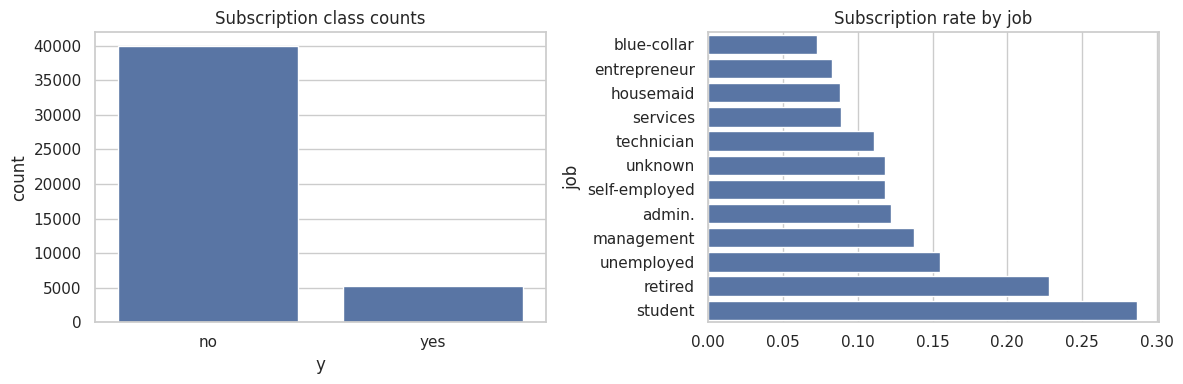

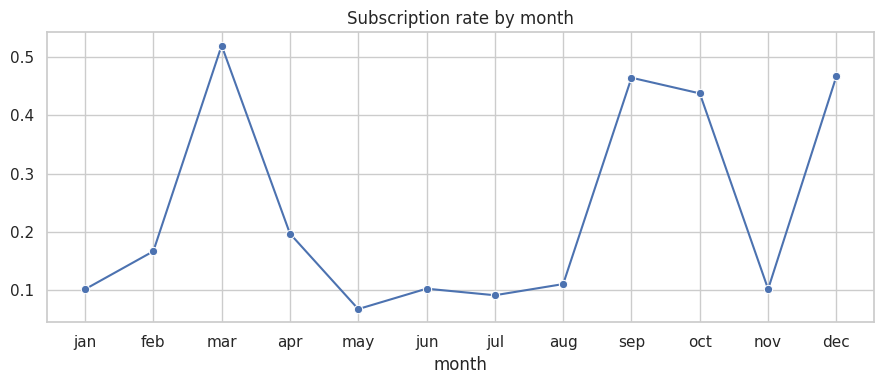

,age,balance,campaign,duration
y,,,,
no,39.0,417.0,2.0,164.0
yes,38.0,733.0,2.0,426.0


In [3]:
fig, axes = plt.subplots(1,2,figsize=(12,4))
sns.countplot(data=df,x="y",order=["no","yes"],ax=axes[0]); axes[0].set_title("Subscription class counts")
rate = df.groupby("job")["subscribed"].mean().sort_values()
sns.barplot(x=rate.values,y=rate.index,ax=axes[1]); axes[1].set_title("Subscription rate by job")
plt.tight_layout(); plt.show()
month_order=["jan","feb","mar","apr","may","jun","jul","aug","sep","oct","nov","dec"]
mrate=df.groupby("month")["subscribed"].mean().reindex(month_order)
plt.figure(figsize=(9,4)); sns.lineplot(x=mrate.index,y=mrate.values,marker="o")
plt.title("Subscription rate by month"); plt.tight_layout(); plt.show()
display(df.groupby("y")[["age","balance","campaign","duration"]].median().round(2))


## 3. Unsupervised customer segmentation

In [4]:
seg = df.copy()
num = ["age","balance","campaign","pdays_clean","previous","day","previously_contacted"]
cat = ["job","marital","education","default","housing","loan","contact","month","poutcome"]
Xs = seg[num+cat].copy()
for col in ["age","balance","campaign","pdays_clean","previous","day"]:
    lo,hi=Xs[col].quantile([.01,.99]); Xs[col]=Xs[col].clip(lo,hi)
pre_seg=ColumnTransformer([
    ("num",Pipeline([("imp",SimpleImputer(strategy="median")),("scale",RobustScaler())]),num),
    ("cat",Pipeline([("imp",SimpleImputer(strategy="most_frequent")),("ohe",OneHotEncoder(handle_unknown="ignore"))]),cat)
])
Z=pre_seg.fit_transform(Xs)
km=KMeans(n_clusters=4,random_state=42,n_init=10)
seg["Cluster"]=km.fit_predict(Z)
print("Silhouette:",round(silhouette_score(Z,seg["Cluster"],sample_size=min(5000,Z.shape[0]),random_state=42),4))
display(seg.groupby("Cluster").agg(customers=("y","size"),mean_age=("age","mean"),
    median_balance=("balance","median"),subscription_rate=("subscribed","mean")).round(3))


Silhouette: 0.8845


,customers,mean_age,median_balance,subscription_rate
Cluster,,,,
0,39378,41.028,432.0,0.102
1,2214,38.738,391.5,0.139
2,2182,42.074,907.0,0.354
3,1437,40.085,475.0,0.127


## 4. Supervised prediction — leakage-safe model comparison

In [5]:
target=(df["y"]=="yes").astype(int)
Xp=df.drop(columns=["y","subscribed","duration"]).copy()
Xp["previously_contacted"]=(Xp["pdays"]!=-1).astype(int)
Xp["pdays"]=Xp["pdays"].where(Xp["pdays"]!=-1,np.nan)
num_model=["age","balance","day","campaign","pdays","previous","previously_contacted"]
cat_model=[c for c in Xp.columns if c not in num_model]
Xtr,Xte,ytr,yte=train_test_split(Xp,target,test_size=.20,random_state=42,stratify=target)
pre=ColumnTransformer([
    ("num",Pipeline([("imp",SimpleImputer(strategy="median")),("scale",StandardScaler())]),num_model),
    ("cat",Pipeline([("imp",SimpleImputer(strategy="most_frequent")),("ohe",OneHotEncoder(handle_unknown="ignore"))]),cat_model)
])
models={
 "Logistic Regression":Pipeline([("pre",pre),("clf",LogisticRegression(max_iter=1500,class_weight="balanced",solver="liblinear"))]),
 "Random Forest":Pipeline([("pre",pre),("clf",RandomForestClassifier(n_estimators=250,min_samples_leaf=3,class_weight="balanced_subsample",n_jobs=-1,random_state=42))])
}
for model in models.values(): model.fit(Xtr,ytr)
for name,model in models.items():
    prob=model.predict_proba(Xte)[:,1]; pred=(prob>=.5).astype(int)
    print("\\n",name, "ROC-AUC",round(roc_auc_score(yte,prob),4),"PR-AUC",round(average_precision_score(yte,prob),4))
    print(classification_report(yte,pred,target_names=["no","yes"],zero_division=0))


\n Logistic Regression ROC-AUC 0.7698 PR-AUC 0.4185
              precision    recall  f1-score   support

          no       0.94      0.78      0.86      7985
         yes       0.28      0.63      0.38      1058

    accuracy                           0.77      9043
   macro avg       0.61      0.71      0.62      9043
weighted avg       0.86      0.77      0.80      9043

\n Random Forest ROC-AUC 0.8 PR-AUC 0.4512
              precision    recall  f1-score   support

          no       0.94      0.89      0.91      7985
         yes       0.40      0.56      0.47      1058

    accuracy                           0.85      9043
   macro avg       0.67      0.72      0.69      9043
weighted avg       0.88      0.85      0.86      9043



## 5. Deep learning — feed-forward neural network

This integrated capstone section uses TensorFlow. It creates separate training, validation and test partitions, fits preprocessing on training data only and trains a regularized dense network. If TensorFlow is not installed in the notebook runtime, install it with `%pip install -q tensorflow` and rerun from the top.


In [6]:
# TensorFlow section
import tensorflow as tf
from tensorflow import keras
from tensorflow.keras import layers
tf.keras.utils.set_random_seed(42)

Xtr2,Xte2,ytr2,yte2=train_test_split(Xp,target,test_size=.20,random_state=42,stratify=target)
Xfit,Xval,yfit,yval=train_test_split(Xtr2,ytr2,test_size=.20,random_state=42,stratify=ytr2)
pre_nn=ColumnTransformer([
    ("num",Pipeline([("imp",SimpleImputer(strategy="median")),("scale",StandardScaler())]),num_model),
    ("cat",Pipeline([("imp",SimpleImputer(strategy="most_frequent")),("ohe",OneHotEncoder(handle_unknown="ignore",sparse_output=False))]),cat_model)
])
A=pre_nn.fit_transform(Xfit).astype("float32")
B=pre_nn.transform(Xval).astype("float32")
T=pre_nn.transform(Xte2).astype("float32")
classes,counts=np.unique(yfit,return_counts=True)
weights={int(c):float(len(yfit)/(len(classes)*n)) for c,n in zip(classes,counts)}
nn=keras.Sequential([layers.Input(shape=(A.shape[1],)),layers.Dense(128,activation="relu"),
    layers.BatchNormalization(),layers.Dropout(.35),layers.Dense(64,activation="relu"),
    layers.Dropout(.25),layers.Dense(1,activation="sigmoid")])
nn.compile(optimizer=keras.optimizers.Adam(1e-3),loss="binary_crossentropy",
    metrics=[keras.metrics.BinaryAccuracy(name="accuracy"),keras.metrics.AUC(name="roc_auc"),
             keras.metrics.AUC(name="pr_auc",curve="PR")])
hist=nn.fit(A,yfit,validation_data=(B,yval),epochs=80,batch_size=256,class_weight=weights,
    callbacks=[keras.callbacks.EarlyStopping(monitor="val_pr_auc",mode="max",patience=7,restore_best_weights=True)],
    verbose=1)
p=nn.predict(T,verbose=0).ravel(); pred=(p>=.5).astype(int)
print("NN ROC-AUC:",round(roc_auc_score(yte2,p),4),"PR-AUC:",round(average_precision_score(yte2,p),4))
print(classification_report(yte2,pred,target_names=["no","yes"],zero_division=0))


Epoch 1/80
114/114 ━━━━━━━━━━━━━━━━━━━━ 3s 11ms/step - accuracy: 0.6672 - loss: 0.6615 - pr_auc: 0.2779 - roc_auc: 0.7028 - val_accuracy: 0.5981 - val_loss: 0.6733 - val_pr_auc: 0.4046 - val_roc_auc: 0.7690
Epoch 2/80
114/114 ━━━━━━━━━━━━━━━━━━━━ 1s 7ms/step - accuracy: 0.7170 - loss: 0.6017 - pr_auc: 0.3503 - roc_auc: 0.7489 - val_accuracy: 0.7661 - val_loss: 0.6205 - val_pr_auc: 0.4227 - val_roc_auc: 0.7855
Epoch 3/80
114/114 ━━━━━━━━━━━━━━━━━━━━ 1s 7ms/step - accuracy: 0.7386 - loss: 0.5746 - pr_auc: 0.3838 - roc_auc: 0.7704 - val_accuracy: 0.7893 - val_loss: 0.5729 - val_pr_auc: 0.4360 - val_roc_auc: 0.7903
Epoch 4/80
114/114 ━━━━━━━━━━━━━━━━━━━━ 1s 7ms/step - accuracy: 0.7480 - loss: 0.5609 - pr_auc: 0.4061 - roc_auc: 0.7824 - val_accuracy: 0.8065 - val_loss: 0.5260 - val_pr_auc: 0.4414 - val_roc_auc: 0.7927
Epoch 5/80
114/114 ━━━━━━━━━━━━━━━━━━━━ 1s 7ms/step - accuracy: 0.7576 - loss: 0.5537 - pr_auc: 0.4243 - roc_auc: 0.7881 - val_accuracy: 0.7910 - val_loss: 0.5434 - val_pr_auc

## 6. Integrated evaluation, interpretation and recommendations

Compare cluster profiles, traditional model metrics and neural-network metrics. The supervised models estimate subscription propensity, while clustering is descriptive and does not predict the target. These methods answer different questions and should not be conflated.

Potential recommendations:
1. Use customer segments to understand patterns and formulate campaign hypotheses, not as permanent labels.
2. Evaluate targeting policies using validation data and business capacity constraints; do not use accuracy alone.
3. Use pre-call features for decisions made before a call. Do not include call duration in that setting.
4. Monitor performance and calibration over time because campaign response may change with season, product, economic conditions and customer mix.
5. Review subgroup error rates and customer privacy implications before operational use.
